# Introduction to Regression Analysis

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. What is Linear Regression?

Linear regression models the relationship between a **dependent variable $y$** and one or more **independent variables $x$**.

- In **simple linear regression** there is **one predictor** ($x$).
- The relationship is assumed to be **linear**: each extra unit of $x$ changes $y$ by the same amount.
- The **errors** $\epsilon_i$ are assumed to be independent, normally distributed, with constant variance (homoscedasticity).

## 2. Mathematical Model

$$
y_i = \beta_0 + \beta_1 x_i + \epsilon_i
$$

- $y_i$: observed value of the dependent variable for observation $i$
- $x_i$: value of the independent variable for observation $i$
- $\beta_0$: intercept (value of $y$ when $x = 0$)
- $\beta_1$: slope (change in $y$ for a one-unit change in $x$)
- $\epsilon_i$: error term, the deviation of the observation from the true line

The **predicted value** is $\hat{y}_i = \hat{\beta}_0 + \hat{\beta}_1 x_i$ and the **residual** is $e_i = y_i - \hat{y}_i$.

## 3. Estimating Coefficients With Ordinary Least Squares (OLS)

OLS picks the line that **minimizes the sum of squared errors**:

$$
SSE = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

Setting the derivatives with respect to $\beta_0$ and $\beta_1$ to zero gives:

$$
\hat{\beta}_1 = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2} = \frac{\text{Cov}(x, y)}{\text{Var}(x)}, \qquad
\hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}
$$

The intercept formula guarantees the line passes through the point $(\bar{x}, \bar{y})$.

**Why squared errors?** Squaring makes all deviations positive, penalises large deviations more heavily, and yields a unique closed-form solution.

## 4. How Good is the Fit? $R^2$

$$
R^2 = 1 - \frac{SSE}{SST} = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}
$$

$R^2$ is the share of the variance in $y$ explained by the model (in simple regression it equals $r^2$).

In [2]:
hours_studied <- c(2, 4, 6, 8, 10, 12, 14)
test_scores <- c(50, 55, 65, 70, 80, 85, 90)
study_data <- data.frame(Hours = hours_studied, Score = test_scores)

# Step 1: means
mean_hours <- mean(study_data$Hours)
mean_score <- mean(study_data$Score)

# Step 2: slope and intercept with the OLS formulas
beta1 <- sum((study_data$Hours - mean_hours) * (study_data$Score - mean_score)) /
         sum((study_data$Hours - mean_hours)^2)
beta0 <- mean_score - beta1 * mean_hours

# Step 3: predictions, residuals and R^2
study_data$Predicted <- beta0 + beta1 * study_data$Hours
study_data$Residual  <- study_data$Score - study_data$Predicted
R2 <- 1 - sum(study_data$Residual^2) / sum((study_data$Score - mean_score)^2)

cat("Slope (beta1)    :", round(beta1, 4), "\n")
cat("Intercept (beta0):", round(beta0, 4), "\n")
cat("R-squared        :", round(R2, 4), " | r^2 =", round(cor(hours_studied, test_scores)^2, 4), "\n\n")
print(round(study_data, 3), row.names = FALSE)

Slope (beta1)    : 3.4821 


Intercept (beta0): 42.8571 


R-squared        : 0.9902  | r^2 = 0.9902 



 Hours Score Predicted Residual
     2    50    49.821    0.179
     4    55    56.786   -1.786
     6    65    63.750    1.250
     8    70    70.714   -0.714
    10    80    77.679    2.321
    12    85    84.643    0.357
    14    90    91.607   -1.607


In [3]:
# The same model with R's built-in lm()
model <- lm(Score ~ Hours, data = study_data)
summary(model)


Call:
lm(formula = Score ~ Hours, data = study_data)

Residuals:
      1       2       3       4       5       6       7 
 0.1786 -1.7857  1.2500 -0.7143  2.3214  0.3571 -1.6071 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  42.8571     1.3832   30.98 6.57e-07 ***
Hours         3.4821     0.1546   22.52 3.21e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.637 on 5 degrees of freedom
Multiple R-squared:  0.9902,	Adjusted R-squared:  0.9883 
F-statistic:   507 on 1 and 5 DF,  p-value: 3.211e-06


**Reading the `summary()` output:**
- *Estimate*: the coefficients (they match our manual calculation).
- *Std. Error* and *t value*: the uncertainty of each coefficient and its t-statistic for $H_0: \beta = 0$.
- *Pr(>|t|)*: p-value. The slope is highly significant.
- *Multiple R-squared*: the $R^2$ we computed.
- *Residual standard error*: the typical size of a residual, in score points.

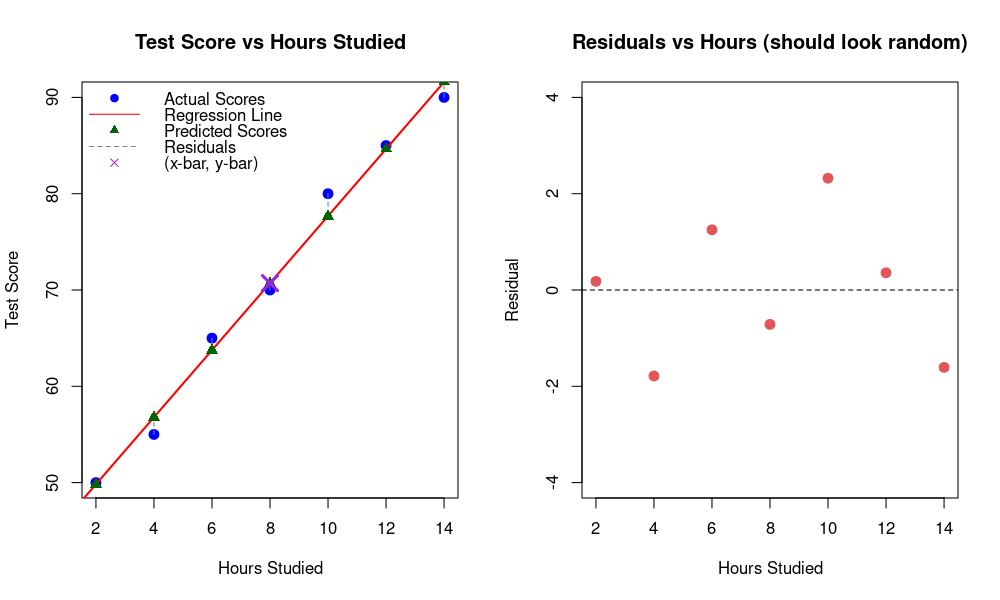

In [4]:
par(mfrow = c(1, 2))
plot(study_data$Hours, study_data$Score, main = "Test Score vs Hours Studied",
     xlab = "Hours Studied", ylab = "Test Score", pch = 19, col = "blue", cex = 1.3)
abline(a = beta0, b = beta1, col = "red", lwd = 2)
segments(study_data$Hours, study_data$Score, study_data$Hours, study_data$Predicted, col = "grey50", lty = 2)
points(study_data$Hours, study_data$Predicted, col = "darkgreen", pch = 17, cex = 1.2)
points(mean_hours, mean_score, pch = 4, cex = 2, lwd = 3, col = "purple")
legend("topleft", legend = c("Actual Scores", "Regression Line", "Predicted Scores", "Residuals", "(x-bar, y-bar)"),
       col = c("blue", "red", "darkgreen", "grey50", "purple"), pch = c(19, NA, 17, NA, 4),
       lty = c(NA, 1, NA, 2, NA), bty = "n")

plot(study_data$Hours, study_data$Residual, pch = 19, col = "#E15759", cex = 1.3, ylim = c(-4, 4),
     main = "Residuals vs Hours (should look random)", xlab = "Hours Studied", ylab = "Residual")
abline(h = 0, lty = 2)

## 5. Making Predictions — and Their Uncertainty

`predict()` can return two kinds of intervals:
- **Confidence interval**: uncertainty about the **average** score of all students who study $x$ hours.
- **Prediction interval**: uncertainty about **one individual** student's score — always wider, because it also includes the individual's own random variation.

In [5]:
new_students <- data.frame(Hours = c(5, 9, 20))
cbind(new_students,
      round(predict(model, new_students, interval = "confidence"), 2),
      round(predict(model, new_students, interval = "prediction")[, -1], 2))

,Hours,fit,lwr,upr,lwr,upr
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,5,60.27,58.28,62.26,55.61,64.92
2,9,74.20,72.56,75.84,69.68,78.71
3,20,112.50,107.47,117.53,105.94,119.06


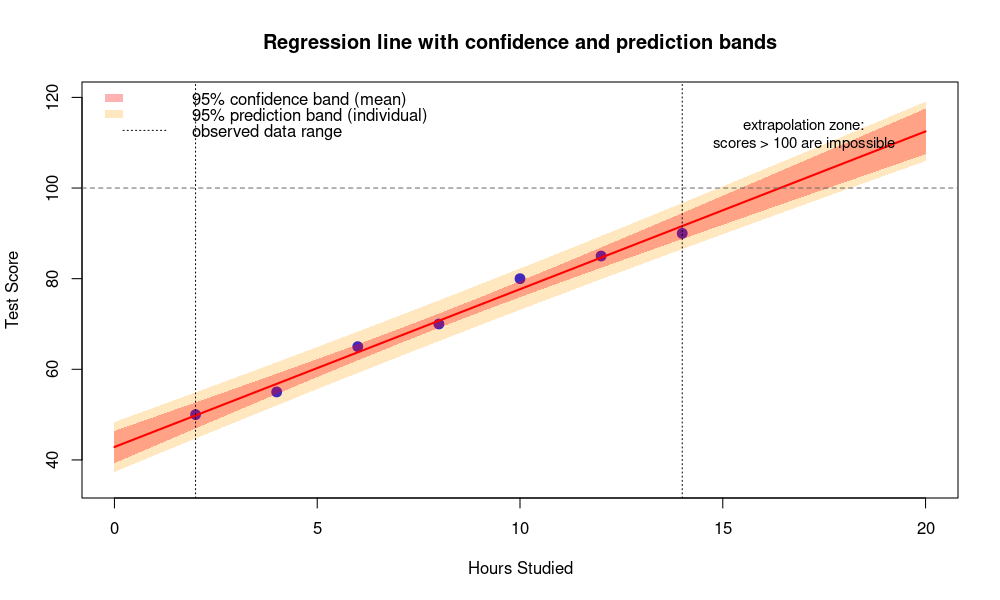

In [6]:
grid <- data.frame(Hours = seq(0, 20, length.out = 200))
ci <- predict(model, grid, interval = "confidence")
pi <- predict(model, grid, interval = "prediction")

par(mfrow = c(1, 1))
plot(study_data$Hours, study_data$Score, pch = 19, col = "blue", cex = 1.3, xlim = c(0, 20), ylim = c(35, 120),
     main = "Regression line with confidence and prediction bands", xlab = "Hours Studied", ylab = "Test Score")
polygon(c(grid$Hours, rev(grid$Hours)), c(pi[, "lwr"], rev(pi[, "upr"])), col = adjustcolor("orange", 0.25), border = NA)
polygon(c(grid$Hours, rev(grid$Hours)), c(ci[, "lwr"], rev(ci[, "upr"])), col = adjustcolor("red", 0.3), border = NA)
lines(grid$Hours, ci[, "fit"], col = "red", lwd = 2)
abline(v = range(study_data$Hours), lty = 3)
abline(h = 100, col = "grey40", lty = 2)
text(17, 112, "extrapolation zone:\nscores > 100 are impossible", cex = 0.9)
legend("topleft", c("95% confidence band (mean)", "95% prediction band (individual)", "observed data range"),
       fill = c(adjustcolor("red", 0.3), adjustcolor("orange", 0.25), NA), border = NA,
       lty = c(NA, NA, 3), bty = "n")

*Insight: The bands widen as you move away from $\bar{x}$, and beyond the observed data (14 hours) the line keeps rising past the maximum possible score of 100. A regression line describes the data you have; it is not a law of nature. Be very careful when **extrapolating**.*

## Real-World Use Case or Analogy

Imagine you are a teacher predicting students' test scores from the hours they studied:

- Each student is a point on the graph.
- The red regression line shows the **average trend**.
- The slope tells you how much the score rises per extra hour of study (about 3.5 points here).
- Residuals are the "surprises": students who did better or worse than their study time predicted.

Real estate pricing works the same way: price ≈ base price + price per square metre × area. The model gives a fair estimate for typical houses, and becomes unreliable for a 2,000 m² mansion if every house in the data was under 200 m².